# 8 — Non-interacting fermions in a harmonic trap

The first fermionic system: N spin-polarised fermions in a 1D harmonic trap,

    H = sum_i ( -1/2 d^2/dx_i^2 + 1/2 x_i^2 ).

Nothing interacts, so the ground state is a single Slater determinant of the lowest N
oscillator orbitals, with E_0 = sum_{n<N} (n + 1/2) = N^2/2.

This notebook introduces the **output convention**: every model returns
`(log_abs, phase)`, with psi = exp(log_abs + i phase). For a real ground state the phase
is 0 or pi, i.e. the sign of the determinant. It comes from `slogdet`, not from training.

Steps: exact Slater state → check antisymmetry and that E_loc is constant (zero
variance) → train `FermionicMLP` × Gaussian envelope → compare energy and density.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")

import tempfile

import flax.linen as nn
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax

# not "raise": the library MLP broadcasts its bias (batch, H) + (H,)

from qvarnet import VMC, SamplingConfig, TrainingConfig, evaluate_result
from qvarnet.analysis.estimators import TrainedWavefunction
from qvarnet.ansatz import FermionicMLP, GaussianEnvelope, LogWavefunction
from qvarnet.physics.hamiltonian.continuous import HarmonicOscillatorHamiltonian
from qvarnet.vmc.training_step import compute_local_energy

n_particles = 3
ham = HarmonicOscillatorHamiltonian(omega=1.0)
E0 = n_particles**2 / 2
print("exact E_0 =", E0)

exact E_0 = 4.5


## The exact Slater determinant

The oscillator orbitals are h_n(x) = p_n(x) exp(-x^2/2), where p_n is a normalised
Hermite polynomial. It follows the stable recurrence

    p_0 = pi^(-1/4),   p_1 = sqrt(2) x p_0,
    p_(n+1) = sqrt(2/(n+1)) x p_n - sqrt(n/(n+1)) p_(n-1).

Since every column of the matrix [h_j(x_i)] shares the Gaussian, the determinant splits as

    log|psi| = log|det p_j(x_i)| - sum_i x_i^2 / 2,    phase = pi if det < 0 else 0,

so we never take the log of a tiny number.

In [2]:
def hermite_poly_matrix(x, n):
    """(..., N) positions -> (..., N, n) with entries p_j(x_i)."""
    p = [jnp.full_like(x, np.pi**-0.25)]
    if n > 1:
        p.append(np.sqrt(2.0) * x * p[0])
    for k in range(1, n - 1):
        p.append(np.sqrt(2.0 / (k + 1)) * x * p[k] - np.sqrt(k / (k + 1)) * p[k - 1])
    return jnp.stack(p, axis=-1)


class ExactSlater(nn.Module):
    n_fermions: int

    @nn.compact
    def __call__(self, x):
        sign, log_det = jnp.linalg.slogdet(hermite_poly_matrix(x, self.n_fermions))
        log_abs = log_det - 0.5 * jnp.sum(x**2, axis=-1)
        return log_abs, jnp.where(sign < 0, jnp.pi, 0.0)  # (...,), (...,)


exact_model = ExactSlater(n_particles)
exact_params = exact_model.init(jax.random.PRNGKey(0), jnp.ones((1, n_particles)))

## Step 1 — checks on the exact state

1. **Antisymmetry.** Swapping two particles must leave log|psi| unchanged and shift the
   phase by pi.
2. **Zero variance.** For the exact eigenstate, E_loc(x) = E_0 at *every* sample. This
   is the sharpest test of the pipeline: sampler, kinetic energy and `slogdet`
   derivatives together. Note that the kinetic energy only ever sees log|psi|.
   In float32 the std is ~5e-4: near a node, ∇²log|psi| and |∇log|psi||² are both
   ~1/r² and cancel. With `jax_enable_x64` it drops to ~2e-13 (checked).
3. **Density.** n(x) = sum_{j<N} h_j(x)^2.

In [3]:
x = jax.random.normal(jax.random.PRNGKey(1), (1000, n_particles))
la, ph = exact_model.apply(exact_params, x)
la_s, ph_s = exact_model.apply(exact_params, x[:, [1, 0, 2]])
assert la.shape == ph.shape == (1000,)
print("swap: max |Δ log|psi||   =", float(jnp.max(jnp.abs(la - la_s))))
print("swap: all phases differ by pi:", bool(jnp.all(jnp.cos(ph - ph_s) == -1)))

wf_ex = TrainedWavefunction(exact_model, exact_params, n_particles=n_particles, n_dim=1, seed=0)
wf_ex.sample(n_chains=512, n_steps=1000, burn_in=100, thinning=4, step_size=0.8)
samples = jnp.asarray(wf_ex.samples)

e_loc = compute_local_energy(ham, exact_params, samples, exact_model.apply)
assert e_loc.shape == (samples.shape[0],)
print(f"E_loc over {e_loc.size} samples: mean {float(e_loc.mean()):.8f}   std {float(e_loc.std()):.2e}   (exact {E0})")

swap: max |Δ log|psi||   = 4.00543212890625e-05
swap: all phases differ by pi: True
IAT: 26.88  mean ESS: 39.6
E_loc over 115200 samples: mean 4.50000191   std 5.48e-04   (exact 4.5)


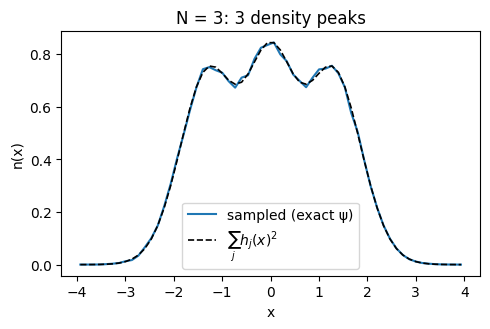

In [4]:
def density_exact(grid, n):
    p = np.asarray(hermite_poly_matrix(jnp.asarray(grid), n))  # (G, n)
    return np.sum(p**2, axis=-1) * np.exp(-grid**2)

centers, dens = wf_ex.density(bins=60, value_range=(-4, 4))
fig, ax = plt.subplots(figsize=(5, 3.4))
ax.plot(centers, dens, lw=1.5, label="sampled (exact ψ)")
ax.plot(centers, density_exact(centers, n_particles), "k--", lw=1.2, label=r"$\sum_j h_j(x)^2$")
ax.set(xlabel="x", ylabel="n(x)", title=f"N = {n_particles}: {n_particles} density peaks")
ax.legend()
fig.tight_layout()

## Step 2 — train a FermionicMLP

The ansatz is one Slater determinant of learned orbitals, phi_j(x_i) = MLP(x_i)_j, shared
across particles. Its orbitals are bounded (tanh), so the trap's decay comes from a
Gaussian envelope added in log space:

    log|psi| = log|det phi_j(x_i)| - alpha^2 sum_i x_i^2,    phase from the determinant sign.

The exact state is in this family: a determinant is unchanged by linear mixing of its
columns, so the MLP only has to span the polynomials of degree < N.

In [5]:
psi = LogWavefunction(
    network=FermionicMLP(architecture=[16], n_fermions=n_particles, n_dim=1),
    envelope=GaussianEnvelope(),
)
shape = (1000, n_particles)
sampling = SamplingConfig(step_size=0.5, chain_length=21, thermalization_steps=20, thinning_factor=1)
n_epochs = 2000

result = VMC(
    shape=shape,
    model=psi,
    optimizer=optax.adam(optax.cosine_decay_schedule(2e-2, n_epochs, alpha=0.05)),
    hamiltonian=ham,
    training_config=TrainingConfig(
        n_epochs=n_epochs, rng_seed=0, checkpoint_path=tempfile.mkdtemp(),
        is_update_step_size=True, print_summary=False,
    ),
    sampler_params=sampling,
).run()

ev = evaluate_result(result, model=psi, hamiltonian=ham, shape=shape, sampling_config=sampling)
print(f"E = {ev.energy:.5f} ± {ev.error:.5f}   exact {E0}   σ_E = {ev.sigma:.4f}   acceptance {ev.acceptance:.2f}")

100%|██████████| 2000/2000 [00:19<00:00, 103.81it/s, E=4.5026, sigma_E=0.1210]


E = 4.50298 ± 0.00008   exact 4.5   σ_E = 0.1151   acceptance 0.50


IAT: 76.98  mean ESS: 6.5


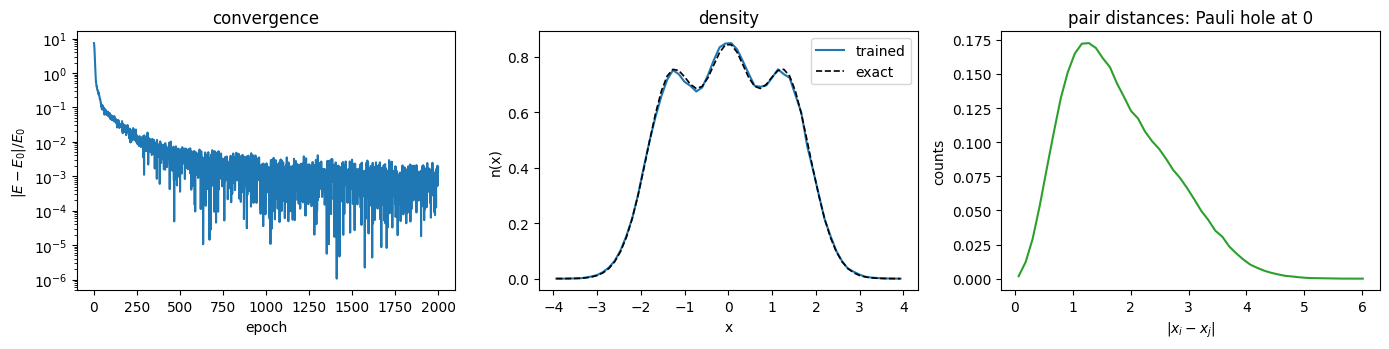

In [6]:
energies = np.asarray(result.history.get("energy"))
wf = TrainedWavefunction.from_result(psi, result, n_particles=n_particles, n_dim=1, seed=0)
wf.sample(n_chains=512, n_steps=1000, burn_in=100, thinning=4)
c, d = wf.density(bins=60, value_range=(-4, 4))
r, g = wf.pair_correlation(bins=50)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].semilogy(np.abs(energies - E0) / E0)
ax[0].set(xlabel="epoch", ylabel=r"$|E - E_0| / E_0$", title="convergence")
ax[1].plot(c, d, lw=1.5, label="trained")
ax[1].plot(c, density_exact(c, n_particles), "k--", lw=1.2, label="exact")
ax[1].set(xlabel="x", ylabel="n(x)", title="density")
ax[1].legend()
ax[2].plot(r, g, lw=1.5, color="tab:green")
ax[2].set(xlabel=r"$|x_i - x_j|$", ylabel="counts", title="pair distances: Pauli hole at 0")
fig.tight_layout()

## Step 3 — orbitals or just the wavefunction? OBDM and g(x, y)

Orbitals one by one cannot be compared: det[chi_j(x_i)] is unchanged (up to a constant)
under any invertible mixing chi → chi A, so the network is free to return any mix of the h_j.
Two-point functions remove that freedom. For a single Slater determinant with orthonormal
orbitals phi_j,

    rho_1(x, y) = sum_{j<N} phi_j(x) phi_j(y)                (OBDM = projector on the occupied space)
    rho_2(x, y) = rho(x) rho(y) - rho_1(x, y)^2              (Wick)
    g(x, y)     = rho_2 / (rho(x) rho(y)) = 1 - rho_1^2 / (rho(x) rho(y)).

So the exact references are analytic, and both are blind to the mixing: they depend only on
span{phi_j}. If the trained rho_1 matches, the network has the right orbitals (as a space).

The natural occupations (eigenvalues of rho_1) are 1 (N times) and 0 for *any* determinant,
right orbitals or not. They check the estimator, not the training.

- `obdm` uses ratios psi(..y..)/psi(..x..), which change sign across nodes. It now takes
  the phase into account (`TrainedWavefunction.phase`); without it the result is wrong for fermions.
- `pair_correlation_grid` only histograms |psi|^2 samples: sign-free.
- Noise floor: the same MC estimators run on the **exact** psi, with the same number of samples.
  A trained-vs-analytic residual at that level carries no information.

In [ ]:
grid = np.linspace(-4, 4, 61)
dx = grid[1] - grid[0]

h = np.asarray(hermite_poly_matrix(jnp.asarray(grid), n_particles)) * np.exp(-(grid**2) / 2)[:, None]
assert h.shape == (grid.size, n_particles)
rho1_ex = h @ h.T  # (G, G)
rho_ex = np.diag(rho1_ex)
g_ex = 1 - rho1_ex**2 / np.outer(rho_ex, rho_ex)

n_obdm = 10_000  # OBDM costs n_obdm * G * N evaluations of psi
est = {}
def rms(a):
    return float(np.sqrt(np.nanmean(a**2)))


for name, w in [("exact ψ (MC)", wf_ex), ("trained", wf)]:
    _, rho1 = w.obdm(grid, samples=w.samples[:n_obdm])
    occ, _ = w.natural_orbitals()
    _, g = w.pair_correlation_grid(grid)  # nan where too few pairs
    est[name] = rho1, g
    print(f"{name:13s} ∫ρ₁(x,x) = {np.trace(rho1) * dx:.3f}   occupations {np.array2string(occ[:n_particles + 2], precision=3)}"
          f"   rms Δρ₁ = {rms(rho1 - rho1_ex):.4f}   rms Δg = {rms(g - g_ex):.4f}")
print(f"analytic      ∫ρ₁(x,x) = {np.trace(rho1_ex) * dx:.3f}   (N = {n_particles}, grid truncated at ±4)")
print("exact ψ (MC) rows = noise + binning floor of each estimator")

rho1_tr, g_tr = est["trained"]
g_ex = np.where(np.isnan(g_tr), np.nan, g_ex)  # 0/0 in the empty tails
v1 = np.max(np.abs(rho1_ex))
d_rho = np.percentile(np.abs(rho1_tr - rho1_ex), 99)
d_g = np.nanpercentile(np.abs(g_tr - g_ex), 99)
ext = [grid[0], grid[-1], grid[0], grid[-1]]
panels = [
    [(rho1_ex, r"$\rho_1$ exact", "coolwarm", -v1, v1), (rho1_tr, r"$\rho_1$ trained", "coolwarm", -v1, v1),
     (rho1_tr - rho1_ex, r"$\rho_1$ trained − exact", "coolwarm", -d_rho, d_rho)],
    [(g_ex, r"$g$ exact", "Blues", 0, 1.2), (g_tr, r"$g$ trained", "Blues", 0, 1.2),
     (g_tr - g_ex, r"$g$ trained − exact", "coolwarm", -d_g, d_g)],
]
fig, ax = plt.subplots(2, 3, figsize=(13, 8))
for r, row in enumerate(panels):
    for c, (z, title, cmap, lo, hi) in enumerate(row):
        im = ax[r, c].imshow(z, origin="lower", extent=ext, cmap=cmap, vmin=lo, vmax=hi)
        ax[r, c].set(title=title, xlabel="x", ylabel="y" if c == 0 else None)
        fig.colorbar(im, ax=ax[r, c], shrink=0.8)
fig.tight_layout()

## What the sign did — and did not do

- Training, sampling, kinetic energy and the QGT used only log|psi|. That is exact for a
  real psi, because the sign is constant between nodes. The phase output went unused here,
  apart from the antisymmetry check.
- Antisymmetry is built in by the determinant, not learned. The Pauli hole in the pair
  distances (no weight at |x_i - x_j| → 0) comes for free.
- **Sign-aware estimators:** anything that takes ratios psi(x')/psi(x) at different
  configurations needs the phase. `obdm`, `obdm_displacement`, `natural_orbitals` and
  `condensate_fraction` now use Re psi'/psi = exp(Δ log|psi|) cos(Δ phase). That is exact for
  a real psi; a complex psi (t-VMC) will need a complex rho_1.